# Productivity range
One productivity range per individual: the years between which they were active. It is taken from the first source available, in this order:

1. "fl." in the Wikidata description with two dates ("fl. 1545–1565").
2. The first and last of the individual's work dates, cleaned with the rules of notebook 02, section 4.

Only dates precise to the year or decade are used; a decade counts as its middle year. Ranges shorter than 2 years are removed: they point to a dating problem more than to a real productivity window. Wikidata values only.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5
FIRST_CENTURY = -1000
LAST_CENTURY = 2000
METHODS = ['"fl." with two dates', 'First to last work date']
MIN_RANGE = 2
CUTOFF = 1500
ENRICHED_DB_PATH = '../data/cultura/humans_clean_enriched_v3.duckdb'
CENTURY_WIDTH = 100
FIRST_PLOT_CENTURY, LAST_PLOT_CENTURY = -800, 1800
LAST_YEAR = 1899
LENGTH_MAX = 80
MIN_INDIVIDUALS = 5

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)
apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)
database_size = connection.execute('SELECT count(*) FROM individual').fetchone()[0]
print(f'{database_size:,} individuals in the database')

13,002,897 individuals in the database


## Load the data
### 1. First and last cleaned work dates
The cleaning of notebook 02, section 4: lifetime check, publication dates checked against inceptions, inception spans over 100 years dropped. A decade date placed at its middle year is kept within the individual's birth and death.

In [2]:
LIFETIME_LIMIT = 100

connection.execute(f'''
    CREATE OR REPLACE TEMP TABLE clean_work AS
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year
        FROM individual
    ),
    dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               CASE WHEN work.inception.precision IN ('day', 'month', 'year', 'decade') THEN work.inception.year END AS inception_year,
               CASE WHEN work.publication_date.precision IN ('day', 'month', 'year', 'decade') THEN work.publication_date.year END AS publication_year,
               work.inception.precision AS inception_precision,
               work.publication_date.precision AS publication_precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    dated_with_source AS (
        SELECT qid, work_qid,
               coalesce(inception_year, publication_year) AS year,
               CASE WHEN inception_year IS NOT NULL THEN 'inception' ELSE 'publication' END AS source,
               CASE WHEN inception_year IS NOT NULL THEN inception_precision ELSE publication_precision END AS precision
        FROM dated
        WHERE coalesce(inception_year, publication_year) IS NOT NULL
    ),
    first_inception AS (
        SELECT qid, min(year) AS first_inception_year
        FROM dated_with_source
        WHERE source = 'inception'
        GROUP BY qid
    ),
    kept AS (
        SELECT dated_with_source.*, lifetime.birth_year, lifetime.death_year
        FROM dated_with_source
        JOIN lifetime ON lifetime.qid = dated_with_source.qid
        LEFT JOIN first_inception ON first_inception.qid = dated_with_source.qid
        WHERE (first_inception.qid IS NOT NULL OR lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL)
          AND CASE
              WHEN lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL THEN
                  dated_with_source.year BETWEEN coalesce(lifetime.birth_year, lifetime.death_year - {LIFETIME_LIMIT})
                                             AND coalesce(lifetime.death_year, lifetime.birth_year + {LIFETIME_LIMIT})
              WHEN dated_with_source.source = 'publication' THEN
                  abs(dated_with_source.year - first_inception.first_inception_year) <= {LIFETIME_LIMIT}
              ELSE TRUE
          END
    ),
    inception_only_too_long AS (
        SELECT qid
        FROM kept
        WHERE birth_year IS NULL AND death_year IS NULL
        GROUP BY qid
        HAVING bool_and(source = 'inception') AND max(year) - min(year) > {LIFETIME_LIMIT}
    )
    SELECT *
    FROM kept
    WHERE qid NOT IN (SELECT qid FROM inception_only_too_long)
''')
work_range = connection.execute('''
    WITH placed AS (
        SELECT qid,
               least(greatest(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END, coalesce(birth_year, -9999)),
                     coalesce(death_year, 9999)) AS year
        FROM clean_work
    )
    SELECT qid, min(year) AS start_year, max(year) AS end_year, count(*) AS works
    FROM placed
    GROUP BY qid
''').pl()
short = work_range.filter(pl.col('end_year') - pl.col('start_year') < MIN_RANGE)
work_range = work_range.filter(pl.col('end_year') - pl.col('start_year') >= MIN_RANGE)
print(f'{work_range.height:,} individuals with a work range of at least {MIN_RANGE} years')
print(f'{short.height:,} left out: range under {MIN_RANGE} years ({short.filter(pl.col("works") == 1).height:,} of them with a single work)')
work_range.sample(5, seed=0)

317,518 individuals with a work range of at least 2 years
267,375 left out: range under 2 years (232,402 of them with a single work)


qid,start_year,end_year,works
str,i64,i64,i64
"""Q43077069""",1978,2019,34
"""Q22111962""",1922,1926,2
"""Q14565302""",1990,2004,3
"""Q51064829""",2001,2023,66
"""Q37828411""",2001,2015,204


### 2. "fl." with two dates
Same parsing as notebooks 01 and 03; a shortened second year is completed from the first ("fl. 1840-60" → 1840 and 1860), except before the common era, where years count down ("fl. 104-89 BCE" → 104 and 89 BCE). "BC", "BCE", "B.C." all mark a date before the common era.

In [3]:
fl_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})(s?)\b(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'
range_pattern = r'\bfl\.[^,;)]*?\d\s*(?:s|st|nd|rd|th|\.)?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?\d'
century_pattern = r'\bfl\.[^,;)]*?\b(\d{1,2})(?:st|nd|rd|th|\.)?\s*(?:-\s*\d{1,2}(?:st|nd|rd|th|\.)?\s*)?(century|centuries|millennium)(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'

fl_text = (
    connection.execute('''
        SELECT entity.qid AS qid, entity.description AS description
        FROM individual
        WHERE regexp_matches(entity.description, '\\bfl\\.')
    ''').pl()
    .with_columns(
        pl.col('description').str.extract_groups(fl_pattern).alias('match'),
        pl.col('description').str.extract_groups(century_pattern).alias('century_match'),
        pl.col('description').str.contains(r'\bfl\.\s*\d{1,2}\.').alias('is_ordinal_century'),
    )
    .with_columns(
        pl.col('match').struct.field('1').cast(pl.Int64).alias('year'),
        pl.col('match').struct.field('2').eq('s').alias('is_decade'),
        pl.col('match').struct.field('3').is_not_null().alias('is_bc'),
        pl.col('century_match').struct.field('1').cast(pl.Int64).alias('ordinal'),
        pl.col('century_match').struct.field('2').eq('millennium').alias('is_millennium'),
        pl.col('century_match').struct.field('3').is_not_null().alias('is_century_bc'),
    )
    .with_columns(
        pl.when(pl.col('is_ordinal_century')).then(None)
        .when(pl.col('is_decade')).then(pl.col('year') + MID_DECADE)
        .otherwise(pl.col('year')).alias('year'))
    .with_columns(pl.when(pl.col('is_bc')).then(-pl.col('year')).otherwise(pl.col('year')).alias('fl_precise_year'))
    .with_columns(
        pl.when(pl.col('is_millennium')).then((pl.col('ordinal') - 1) * 1000)
        .otherwise((pl.col('ordinal') - 1) * 100).alias('coarse_year'))
    .with_columns(
        pl.when(pl.col('is_century_bc')).then(-pl.col('coarse_year') - 100 * (~pl.col('is_millennium')).cast(pl.Int64) - 1000 * pl.col('is_millennium').cast(pl.Int64))
        .otherwise(pl.col('coarse_year')).alias('fl_coarse_year'))
    .select(
        'qid', 'description',
        pl.col('fl_precise_year').is_not_null().alias('fl_precise'),
        (pl.col('fl_precise_year').is_not_null() | pl.col('fl_coarse_year').is_not_null()).alias('fl_any'),
        pl.coalesce('fl_precise_year', 'fl_coarse_year').alias('fl_year'),
        pl.col('description').str.contains(range_pattern).alias('fl_range'),
    )
)
range_years_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})s?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?(\d{1,4})'


def second_year(match):
    first, second = match['1'], match['2']
    if first is None or second is None:
        return None
    if len(second) < len(first):
        second = first[:len(first) - len(second)] + second
    return int(second)


fl_text = fl_text.with_columns(
    pl.col('description').str.extract_groups(range_years_pattern)
    .map_elements(second_year, return_dtype=pl.Int64).alias('second_year'),
    pl.col('description').str.extract_groups(range_years_pattern).struct.field('2').cast(pl.Int64).alias('written_second_year'),
).with_columns(
    pl.when(pl.col('fl_year') < 0).then(-pl.col('written_second_year')).otherwise(pl.col('second_year')).alias('second_year')
).drop('written_second_year')
assert fl_text['qid'].is_unique().all()

fl_range = fl_text.filter(pl.col('fl_precise') & pl.col('fl_range') & pl.col('second_year').is_not_null()).select(
    'qid',
    pl.min_horizontal('fl_year', 'second_year').alias('start_year'),
    pl.max_horizontal('fl_year', 'second_year').alias('end_year'),
)
fl_short = fl_range.filter(pl.col('end_year') - pl.col('start_year') < MIN_RANGE)
fl_range = fl_range.filter(pl.col('end_year') - pl.col('start_year') >= MIN_RANGE)
print(f'{fl_range.height:,} individuals with a "fl." range of at least {MIN_RANGE} years ({fl_short.height:,} shorter ones left out)')
fl_range.sample(5, seed=0)

2,939 individuals with a "fl." range of at least 2 years (134 shorter ones left out)


qid,start_year,end_year
str,i64,i64
"""Q1291928""",1501,1521
"""Q135955862""",1537,1560
"""Q134347275""",1812,1820
"""Q104532728""",1957,1965
"""Q18681485""",1624,1634


## Assign the productivity range
Each individual takes the first method that gives a range.

In [4]:
sources = [fl_range, work_range]
productivity = (
    pl.concat([
        frame.select('qid', 'start_year', 'end_year').with_columns(pl.lit(method).alias('method'), pl.lit(rank).alias('rank'))
        for rank, (method, frame) in enumerate(zip(METHODS, sources))
    ])
    .sort('rank')
    .unique('qid', keep='first', maintain_order=True)
    .drop('rank')
    .with_columns(
        (pl.col('end_year') - pl.col('start_year')).alias('length'),
        ((pl.col('start_year') + pl.col('end_year')) // 2).alias('middle_year'),
    )
)
assert productivity['qid'].is_unique().all()
assert (productivity['length'] >= MIN_RANGE).all()
print(f'{productivity.height:,} individuals get a productivity range ({100 * productivity.height / database_size:.1f}% of the database)')
productivity['length'].describe()

320,404 individuals get a productivity range (2.5% of the database)


statistic,value
str,f64
"""count""",320404.0
"""null_count""",0.0
"""mean""",18.237403
"""std""",13.80725
"""min""",2.0
"""25%""",7.0
"""50%""",15.0
"""75%""",26.0
"""max""",717.0


## Table: individuals getting a productivity range by each method
"Available" counts every individual the method could give a range to; "Assigned" counts those it actually gives one to, after the method ranked above it. The period columns place each range by its middle year; their percentages are out of all ranges in that period.

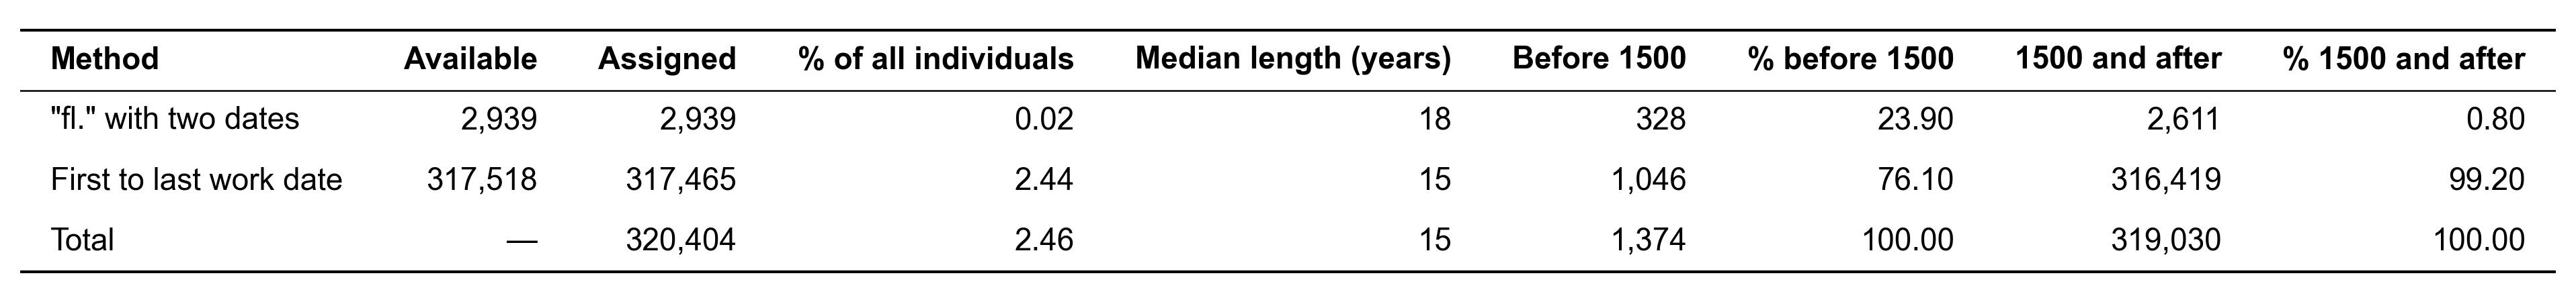

In [5]:
available = {method: frame.height for method, frame in zip(METHODS, sources)}
coverage = (
    productivity.group_by('method').agg(
        pl.len().alias('assigned'),
        pl.col('length').median().alias('median_length'),
        (pl.col('middle_year') < CUTOFF).sum().alias('before'),
        (pl.col('middle_year') >= CUTOFF).sum().alias('after'),
    )
    .with_columns(pl.col('method').replace_strict(available, return_dtype=pl.Int64).alias('available'))
    .sort(pl.col('method').replace_strict(METHODS, list(range(len(METHODS)))))
)
total = productivity.select(
    pl.lit('Total').alias('method'), pl.len().alias('assigned'), pl.col('length').median().alias('median_length'),
    (pl.col('middle_year') < CUTOFF).sum().alias('before'), (pl.col('middle_year') >= CUTOFF).sum().alias('after'),
    pl.lit(None, pl.Int64).alias('available'),
)
coverage = pl.concat([coverage, total.select(coverage.columns)], how='vertical_relaxed')
assert (coverage['before'] + coverage['after'] == coverage['assigned']).all()
before_total, after_total = total['before'][0], total['after'][0]
show_table(coverage.select(
    pl.col('method').alias('Method'),
    pl.col('available').alias('Available'),
    pl.col('assigned').alias('Assigned'),
    (100 * pl.col('assigned') / database_size).round(2).alias('% of all individuals'),
    pl.col('median_length').round(0).cast(pl.Int64).alias('Median length (years)'),
    pl.col('before').alias(f'Before {CUTOFF}'),
    (100 * pl.col('before') / before_total).round(1).alias(f'% before {CUTOFF}'),
    pl.col('after').alias(f'{CUTOFF} and after'),
    (100 * pl.col('after') / after_total).round(1).alias(f'% {CUTOFF} and after'),
), decimals=2)

## Testing: one individual per century and method
For each century, the individual with the most Wikimedia pages whose range starts in the century, once for each method that dates someone there, with their Wikidata birth and death and their description.

In [6]:
connection.register('productivity', productivity.to_arrow())
examples = connection.execute(f'''
    SELECT floor(productivity.start_year / 100)::BIGINT * 100 AS century,
           coalesce(individual.entity.label_en, individual.entity.label_non_en) || ' (' || productivity.qid || ')' AS individual,
           coalesce(list_min([date.year FOR date IN individual.birth_date])::VARCHAR, '?') || ' – '
               || coalesce(list_min([date.year FOR date IN individual.death_date])::VARCHAR, '?') AS lifetime,
           individual.entity.description AS description,
           productivity.start_year, productivity.end_year, productivity.length, productivity.method, productivity.qid
    FROM productivity
    JOIN individual ON individual.entity.qid = productivity.qid
    WHERE floor(productivity.start_year / 100) * 100 BETWEEN {FIRST_CENTURY} AND {LAST_CENTURY}
    QUALIFY row_number() OVER (PARTITION BY floor(productivity.start_year / 100), productivity.method ORDER BY len(individual.sitelink) DESC, productivity.qid) = 1
    ORDER BY century, productivity.method = 'First to last work date'
''').pl()
examples

century,individual,lifetime,description,start_year,end_year,length,method,qid
i64,str,str,str,i64,i64,i64,str,str
-600,"""Chimaera Painter (Q65659082)""","""? – ?""","""Corinthian artist fl. 600-575 BCE""",-600,-575,25,"""""fl."" with two dates""","""Q65659082"""
-600,"""Exekias (Q358541)""","""-501 – -501""","""ancient Athenian vase painter""",-543,-529,14,"""First to last work date""","""Q358541"""
-500,"""Strattis (Q3975908)""","""-499 – -400""","""Athenian poet of Old Comedy (fl. 412–380 BC)""",-412,-380,32,"""""fl."" with two dates""","""Q3975908"""
-500,"""Sophocles (Q7235)""","""-495 – -405""","""ancient Greek playwright""",-462,-441,21,"""First to last work date""","""Q7235"""
-400,"""Appius Claudius Caecus (Q297783)""","""? – -300""","""Roman statesman and writer (fl. c. 312–279 BC)""",-312,-279,33,"""""fl."" with two dates""","""Q297783"""
-400,"""Plato (Q859)""","""-428 – -348""","""4th-century BCE Greek philosopher""",-390,-355,35,"""First to last work date""","""Q859"""
-300,"""Archimedes (Q8739)""","""-286 – -211""","""Greek mathematician and physicist (c. 287 – c. 212 BC)""",-245,-224,21,"""First to last work date""","""Q8739"""
-200,"""Oxyntas (Q7116043)""","""? – ?""","""Numidian prince, son of King Jugurtha (fl. 104-89 BCE)""",-104,-89,15,"""""fl."" with two dates""","""Q7116043"""
-200,"""Cato the Elder (Q180081)""","""-233 – -148""","""Roman politician, soldier and writer (234–149 BC)""",-185,-155,30,"""First to last work date""","""Q180081"""


### Sanity check: ranges longer than a lifetime
Ranges over 100 years cannot be one person's activity; there should be almost none.

In [7]:
print(f"{productivity.filter(pl.col('length') > 100).height:,} ranges longer than 100 years")
productivity.filter(pl.col('length') > 100).group_by('method').len()

7 ranges longer than 100 years


method,len
str,u32
"""""fl."" with two dates""",5
"""First to last work date""",2


### Table: one productivity range per century and method, with an assessment
The assessment compares the range with the individual's best-known period of activity. It was written by Claude from general historical knowledge, not checked against sources: **Yes** = the range covers the main period of activity, **Partial** = inside it but much shorter, **Wrong start** / **Wrong end** = one end falls outside it, **Unknown** = too obscure to judge ("fl." ranges were still checked against their description).

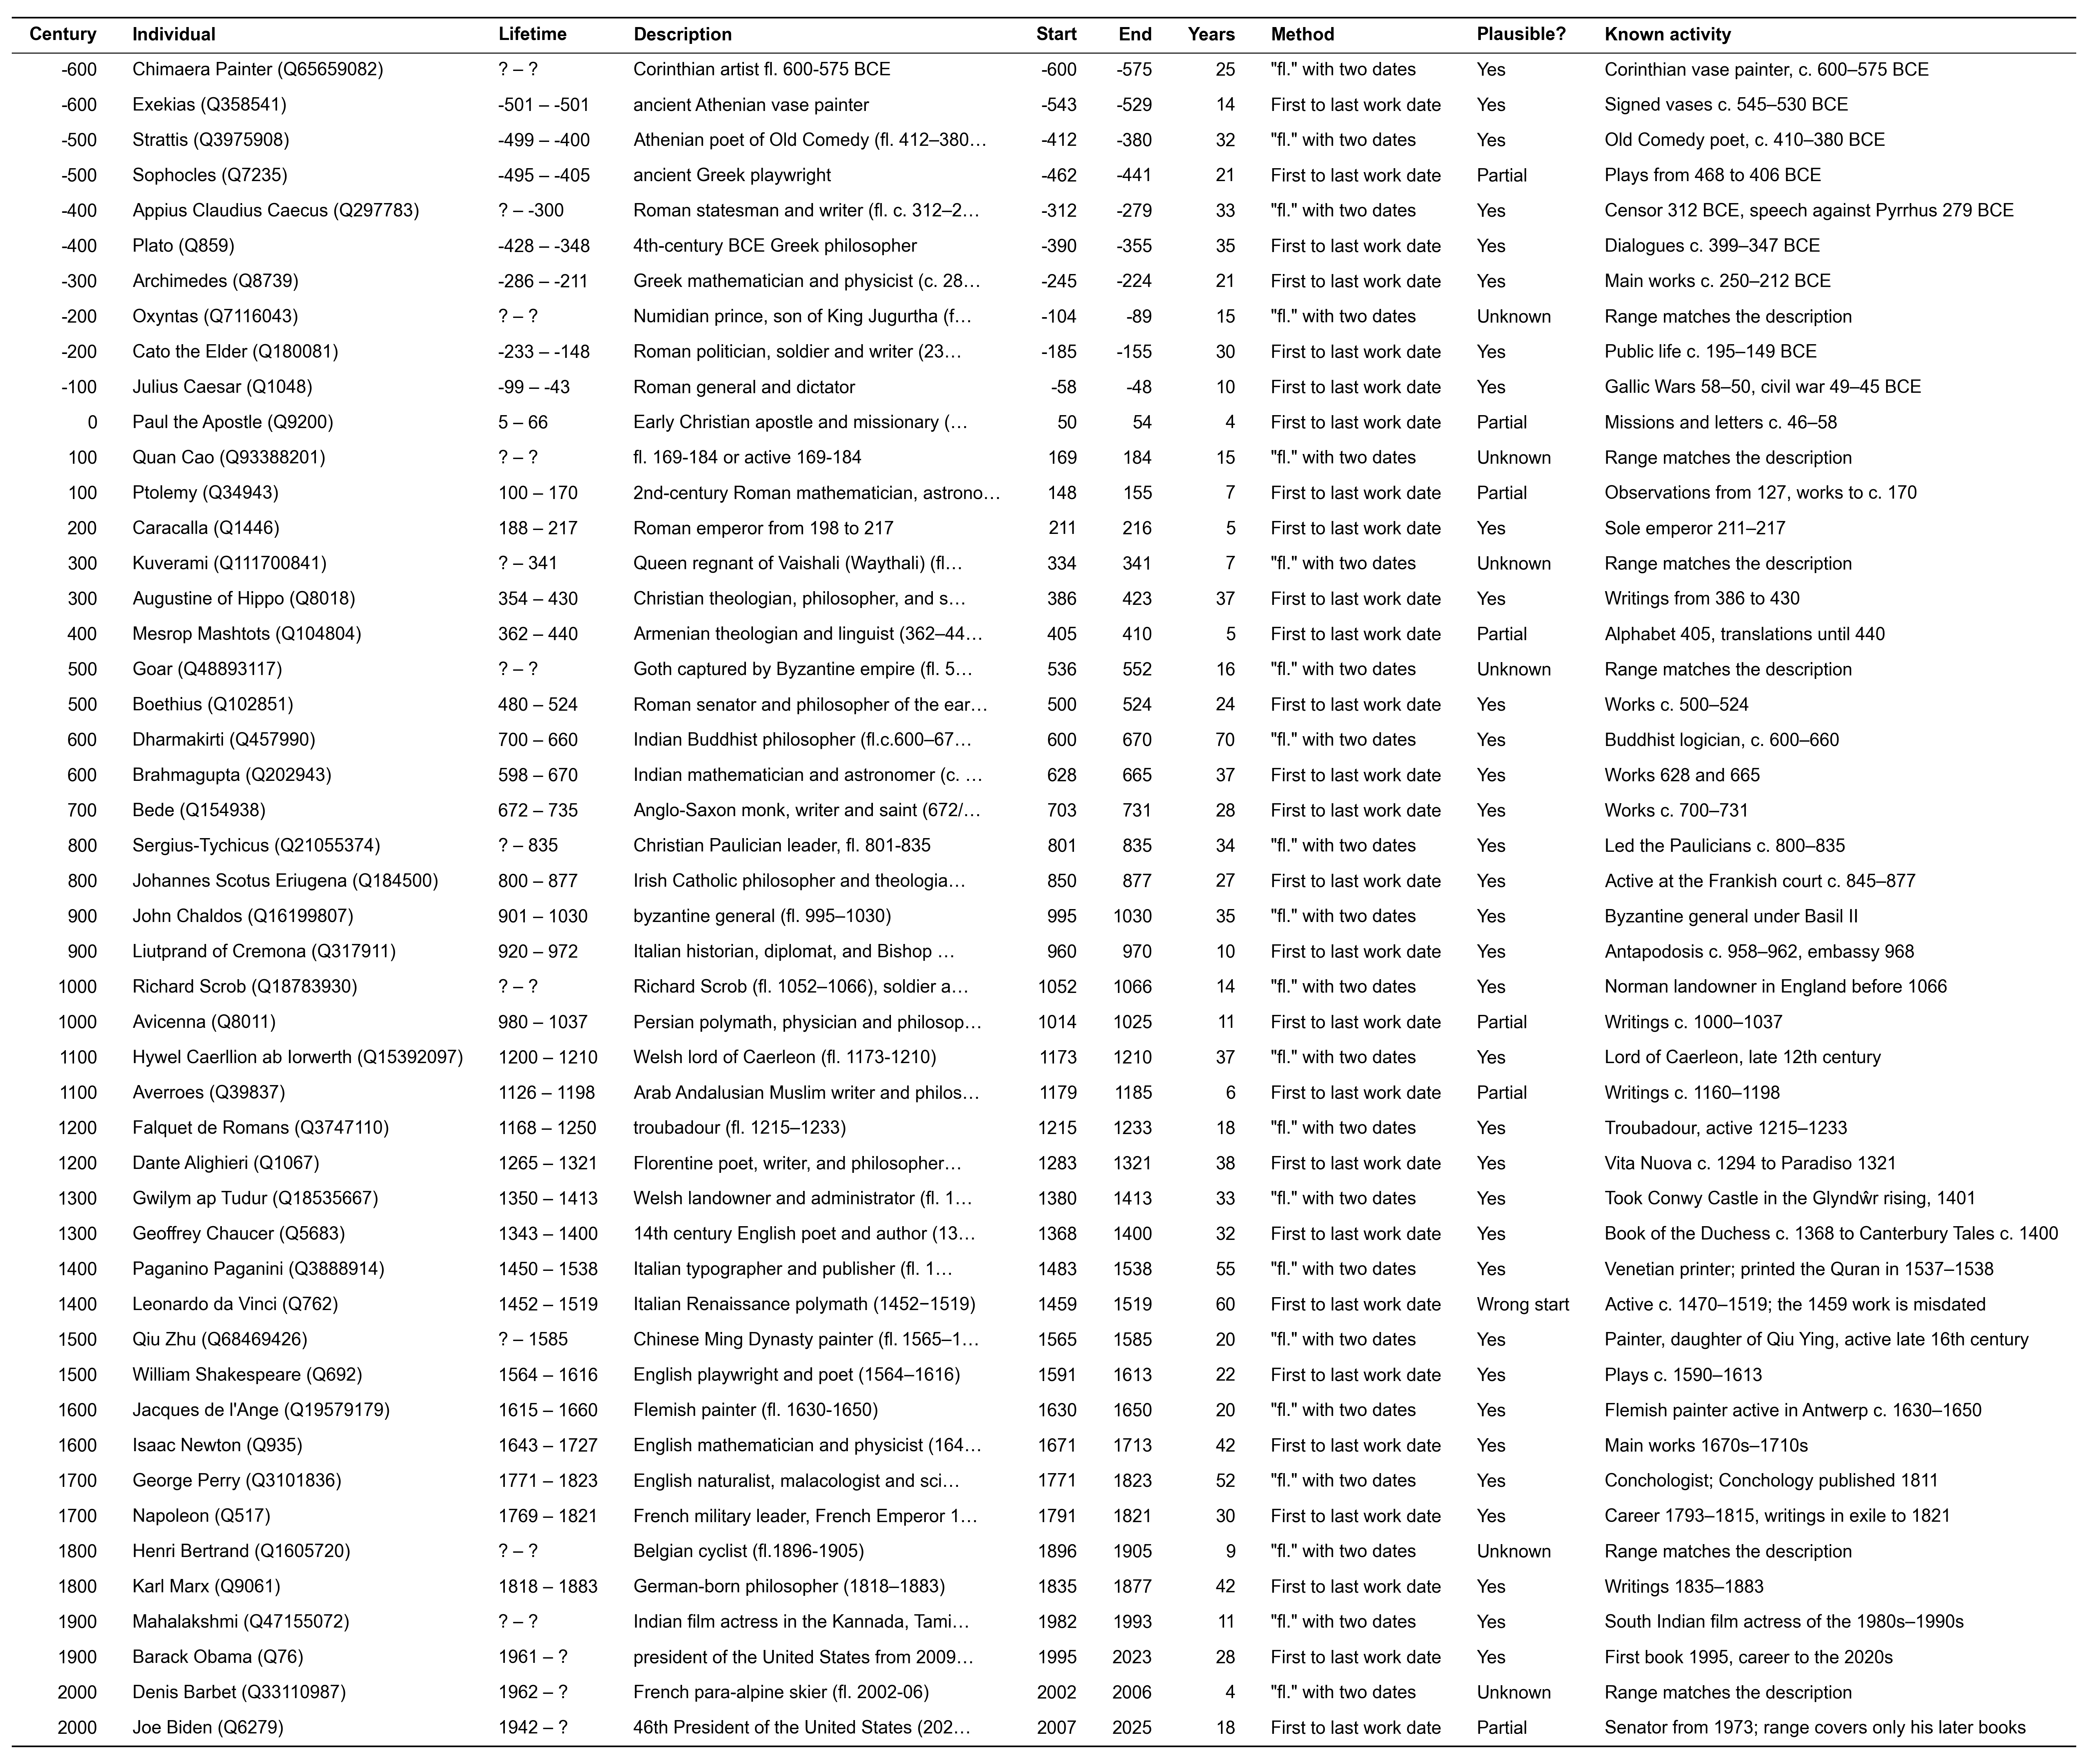

assessment,len
str,u32
"""Yes""",34
"""Partial""",7
"""Unknown""",6
"""Wrong start""",1


In [8]:
EVALUATION = {
    'Q358541': ('Yes', 'Signed vases c. 545–530 BCE'),
    'Q7235': ('Partial', 'Plays from 468 to 406 BCE'),
    'Q859': ('Yes', 'Dialogues c. 399–347 BCE'),
    'Q8739': ('Yes', 'Main works c. 250–212 BCE'),
    'Q180081': ('Yes', 'Public life c. 195–149 BCE'),
    'Q1048': ('Yes', 'Gallic Wars 58–50, civil war 49–45 BCE'),
    'Q9200': ('Partial', 'Missions and letters c. 46–58'),
    'Q34943': ('Partial', 'Observations from 127, works to c. 170'),
    'Q1446': ('Yes', 'Sole emperor 211–217'),
    'Q8018': ('Yes', 'Writings from 386 to 430'),
    'Q104804': ('Partial', 'Alphabet 405, translations until 440'),
    'Q102851': ('Yes', 'Works c. 500–524'),
    'Q202943': ('Yes', 'Works 628 and 665'),
    'Q154938': ('Yes', 'Works c. 700–731'),
    'Q184500': ('Yes', 'Active at the Frankish court c. 845–877'),
    'Q317911': ('Yes', 'Antapodosis c. 958–962, embassy 968'),
    'Q8011': ('Partial', 'Writings c. 1000–1037'),
    'Q39837': ('Partial', 'Writings c. 1160–1198'),
    'Q1067': ('Yes', 'Vita Nuova c. 1294 to Paradiso 1321'),
    'Q5683': ('Yes', 'Book of the Duchess c. 1368 to Canterbury Tales c. 1400'),
    'Q762': ('Wrong start', 'Active c. 1470–1519; the 1459 work is misdated'),
    'Q692': ('Yes', 'Plays c. 1590–1613'),
    'Q935': ('Yes', 'Main works 1670s–1710s'),
    'Q517': ('Yes', 'Career 1793–1815, writings in exile to 1821'),
    'Q9061': ('Yes', 'Writings 1835–1883'),
    'Q76': ('Yes', 'First book 1995, career to the 2020s'),
    'Q6279': ('Partial', 'Senator from 1973; range covers only his later books'),
    'Q65659082': ('Yes', 'Corinthian vase painter, c. 600–575 BCE'),
    'Q3975908': ('Yes', 'Old Comedy poet, c. 410–380 BCE'),
    'Q297783': ('Yes', 'Censor 312 BCE, speech against Pyrrhus 279 BCE'),
    'Q7116043': ('Unknown', 'Range matches the description'),
    'Q93388201': ('Unknown', 'Range matches the description'),
    'Q111700841': ('Unknown', 'Range matches the description'),
    'Q48893117': ('Unknown', 'Range matches the description'),
    'Q457990': ('Yes', 'Buddhist logician, c. 600–660'),
    'Q21055374': ('Yes', 'Led the Paulicians c. 800–835'),
    'Q16199807': ('Yes', 'Byzantine general under Basil II'),
    'Q18783930': ('Yes', 'Norman landowner in England before 1066'),
    'Q15392097': ('Yes', 'Lord of Caerleon, late 12th century'),
    'Q3747110': ('Yes', 'Troubadour, active 1215–1233'),
    'Q18535667': ('Yes', 'Took Conwy Castle in the Glyndŵr rising, 1401'),
    'Q3888914': ('Yes', 'Venetian printer; printed the Quran in 1537–1538'),
    'Q68469426': ('Yes', 'Painter, daughter of Qiu Ying, active late 16th century'),
    'Q19579179': ('Yes', 'Flemish painter active in Antwerp c. 1630–1650'),
    'Q3101836': ('Yes', 'Conchologist; Conchology published 1811'),
    'Q1605720': ('Unknown', 'Range matches the description'),
    'Q47155072': ('Yes', 'South Indian film actress of the 1980s–1990s'),
    'Q33110987': ('Unknown', 'Range matches the description'),
}
assert set(EVALUATION) == set(examples['qid']), set(examples['qid']) ^ set(EVALUATION)

evaluated = examples.with_columns(
    pl.col('qid').replace_strict({qid: verdict for qid, (verdict, _) in EVALUATION.items()}).alias('assessment'),
    pl.col('qid').replace_strict({qid: comment for qid, (_, comment) in EVALUATION.items()}).alias('known_activity'),
)
show_table(evaluated.select(
    pl.col('century').cast(pl.String).alias('Century'),
    pl.col('individual').alias('Individual'),
    pl.col('lifetime').alias('Lifetime'),
    pl.when(pl.col('description').str.len_chars() > 40)
    .then(pl.col('description').str.slice(0, 40) + '…').otherwise(pl.col('description')).alias('Description'),
    pl.col('start_year').cast(pl.String).alias('Start'),
    pl.col('end_year').cast(pl.String).alias('End'),
    pl.col('length').alias('Years'),
    pl.col('method').alias('Method'),
    pl.col('assessment').alias('Plausible?'),
    pl.col('known_activity').alias('Known activity'),
))
evaluated.group_by('assessment').len().sort('len', descending=True)

## Length of the work ranges
Last minus first cleaned work date, for the individuals whose range comes from their works (not "fl."). Each range is placed in the century it starts in, from 800 BC to 1899; later ranges are left out, as many are still open. The occupational category is the most frequent one among the individual's occupations (as in notebooks 03 and 05); categories come from the enriched database, attached read-only. The boxes stop at the whiskers; a few ranges over 100 years stay in the statistics.

In [9]:
connection.execute(f"ATTACH '{ENRICHED_DB_PATH}' AS enriched (READ_ONLY)")
connection.register('ranged', work_range.select('qid').to_arrow())
categories = connection.execute('''
    WITH held AS (
        SELECT individual.entity.qid AS qid,
               unnest(individual.occupation).entity.qid AS occupation_qid,
               generate_subscripts(individual.occupation, 1) AS position
        FROM individual
        JOIN ranged ON ranged.qid = individual.entity.qid
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN enriched.occupation AS occupation ON occupation.entity.qid = held.occupation_qid
        WHERE occupation.meta_occupation IS NOT NULL
        GROUP BY ALL
    )
    SELECT qid, meta_occupation
    FROM counted
    QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
''').pl()

ranges = (
    work_range.join(categories, on='qid', how='left')
    .with_columns(
        pl.col('meta_occupation').fill_null('Other'),
        (pl.col('end_year') - pl.col('start_year')).alias('length'),
        (pl.col('start_year') // CENTURY_WIDTH * CENTURY_WIDTH).alias('century'),
    )
)
assert ranges.height == work_range.height and ranges['qid'].is_unique().all()
print(f'{ranges.height:,} work ranges')
ranges = ranges.filter(pl.col('century').is_between(FIRST_PLOT_CENTURY, LAST_PLOT_CENTURY) & (pl.col('start_year') <= LAST_YEAR))
print(f'{ranges.height:,} starting from {FIRST_PLOT_CENTURY} to {LAST_YEAR}')
ranges.group_by('meta_occupation').len().sort('len', descending=True)

317,518 work ranges
36,076 starting from -800 to 1899


meta_occupation,len
str,u32
"""Culture""",26415
"""Discovery/Science""",7331
"""Leadership""",1558
"""Other""",722
"""Sports/Games""",50


In [10]:
GROUPS = ['All', *OCCUPATION_COLORS]
GROUP_COLORS = {'All': MAIN_LINE_COLOR, **OCCUPATION_COLORS}


def century_label(start):
    number = -start // CENTURY_WIDTH if start < 0 else start // CENTURY_WIDTH + 1
    suffix = 'th' if 10 <= number % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(number % 10, 'th')
    return f'{number}{suffix} c.' + (' BC' if start < 0 else '')


def box_stats(frame, by):
    return (
        frame.group_by(by)
        .agg(
            pl.len().alias('individuals'),
            pl.col('length').quantile(0.25, 'linear').alias('low'),
            pl.col('length').median().alias('median'),
            pl.col('length').quantile(0.75, 'linear').alias('high'),
        )
        .sort(by)
    )


def group_stats(frame):
    everyone = box_stats(frame.with_columns(pl.lit('All').alias('meta_occupation')), 'meta_occupation')
    stats = pl.concat([everyone, box_stats(frame, 'meta_occupation').filter(pl.col('meta_occupation').is_in(GROUPS))])
    return stats.sort(pl.col('meta_occupation').replace_strict(GROUPS, list(range(len(GROUPS)))))


def draw_boxes(ax, values, positions, width, color, medians, quartiles=None):
    ax.boxplot(values, positions=positions, widths=width, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=BAND_ALPHA, edgecolor=color),
               medianprops=dict(color=color, linewidth=2), whiskerprops=dict(color=color), capprops=dict(color=color))
    for x, m in zip(positions, medians):
        ax.annotate(f'{m:.0f}', (x + width * 0.55, m), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE, color=color)
    for x, (low, high) in zip(positions, quartiles or []):
        for q in (low, high):
            ax.annotate(f'{q:.0f}', (x + width * 0.55, q), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)


def plot_centuries(ax, frame, color, show_quartiles=False, show_counts=False, counts_on_top=False):
    stats = box_stats(frame, 'century').filter(pl.col('individuals') >= MIN_INDIVIDUALS)
    starts = stats['century'].to_list()
    x = np.arange(len(starts))
    values = [frame.filter(pl.col('century') == start)['length'].to_numpy() for start in starts]
    quartiles = list(zip(stats['low'], stats['high'])) if show_quartiles else None
    draw_boxes(ax, values, x, 0.6, color, stats['median'], quartiles)
    ax.set_xticks(x)
    labels = [century_label(start) for start in starts]
    if show_counts:
        labels = [f'{label}\n(n = {n:,})' for label, n in zip(labels, stats['individuals'])]
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_xlim(-0.6, len(starts) - 0.2)
    ax.set_ylim(0, LENGTH_MAX)
    if counts_on_top:
        ax.set_ylim(0, LENGTH_MAX + 20)
        ax.set_yticks(range(0, LENGTH_MAX + 1, 20))
        for xi, n in zip(x, stats['individuals']):
            ax.text(xi, LENGTH_MAX + 3, f'{n:,}', rotation=90, ha='center', va='bottom', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)
    ax.grid(axis='y')

### Length of the work ranges, all individuals and by occupational category
#### Data plotted

In [11]:
group_stats(ranges)

meta_occupation,individuals,low,median,high
str,u32,f64,f64,f64
"""All""",36076,10.0,20.0,32.0
"""Culture""",26415,10.0,20.0,34.0
"""Discovery/Science""",7331,10.0,20.0,31.0
"""Leadership""",1558,6.0,13.0,24.0
"""Sports/Games""",50,7.0,15.0,25.0


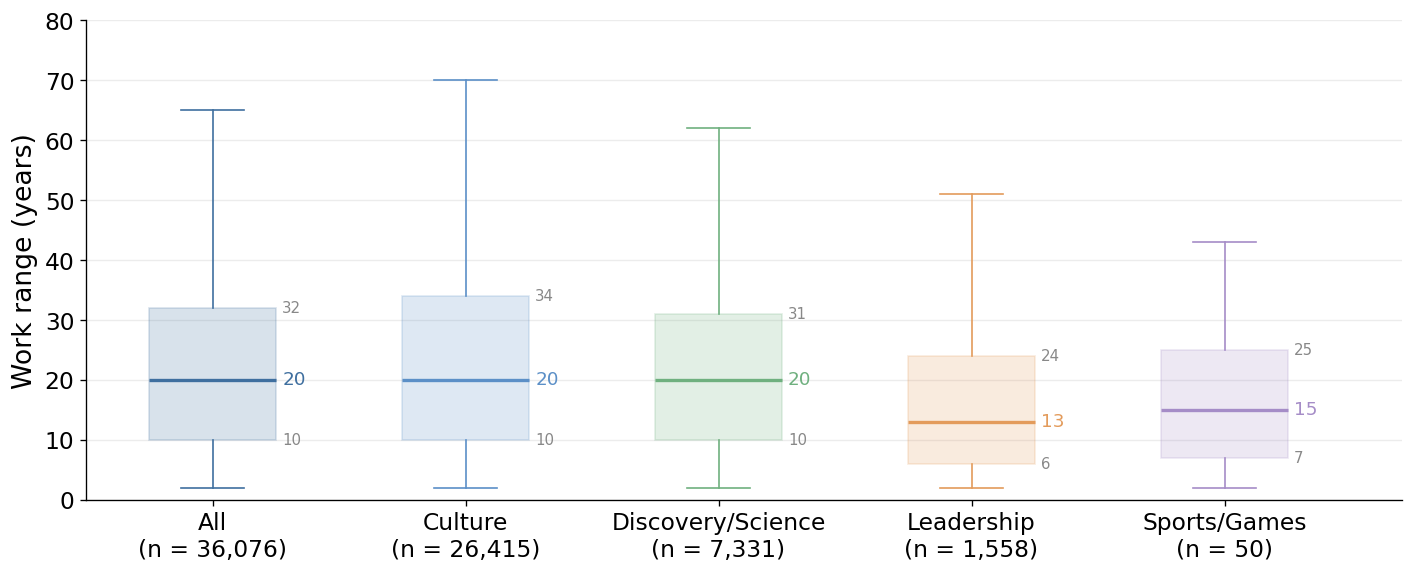

In [12]:
stats = group_stats(ranges)
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, row in enumerate(stats.iter_rows(named=True)):
    group = row['meta_occupation']
    values = ranges if group == 'All' else ranges.filter(pl.col('meta_occupation') == group)
    draw_boxes(ax, [values['length'].to_numpy()], [i], 0.5, GROUP_COLORS[group], [row['median']], [(row['low'], row['high'])])
ax.set_xticks(range(stats.height))
ax.set_xticklabels([f"{row['meta_occupation']}\n(n = {row['individuals']:,})" for row in stats.iter_rows(named=True)])
ax.set_xlim(-0.5, stats.height - 0.3)
ax.set_ylim(0, LENGTH_MAX)
ax.set_ylabel('Work range (years)')
ax.grid(axis='y')
plt.tight_layout()
plt.show()

### Length of the work ranges per century of their start
#### Data plotted

In [13]:
century_stats = box_stats(ranges, 'century')
print(f"{century_stats.filter(pl.col('individuals') < MIN_INDIVIDUALS).height} centuries with fewer than {MIN_INDIVIDUALS} individuals left out")
century_stats

7 centuries with fewer than 5 individuals left out


century,individuals,low,median,high
i64,u32,f64,f64,f64
-600,12,4.0,12.5,21.0
-500,28,10.0,15.0,21.0
-400,13,10.0,14.0,39.0
-300,1,21.0,21.0,21.0
-200,1,30.0,30.0,30.0
-100,8,9.75,11.0,21.75
0,3,3.5,4.0,5.5
100,4,13.75,20.5,26.5
200,2,9.5,14.0,18.5


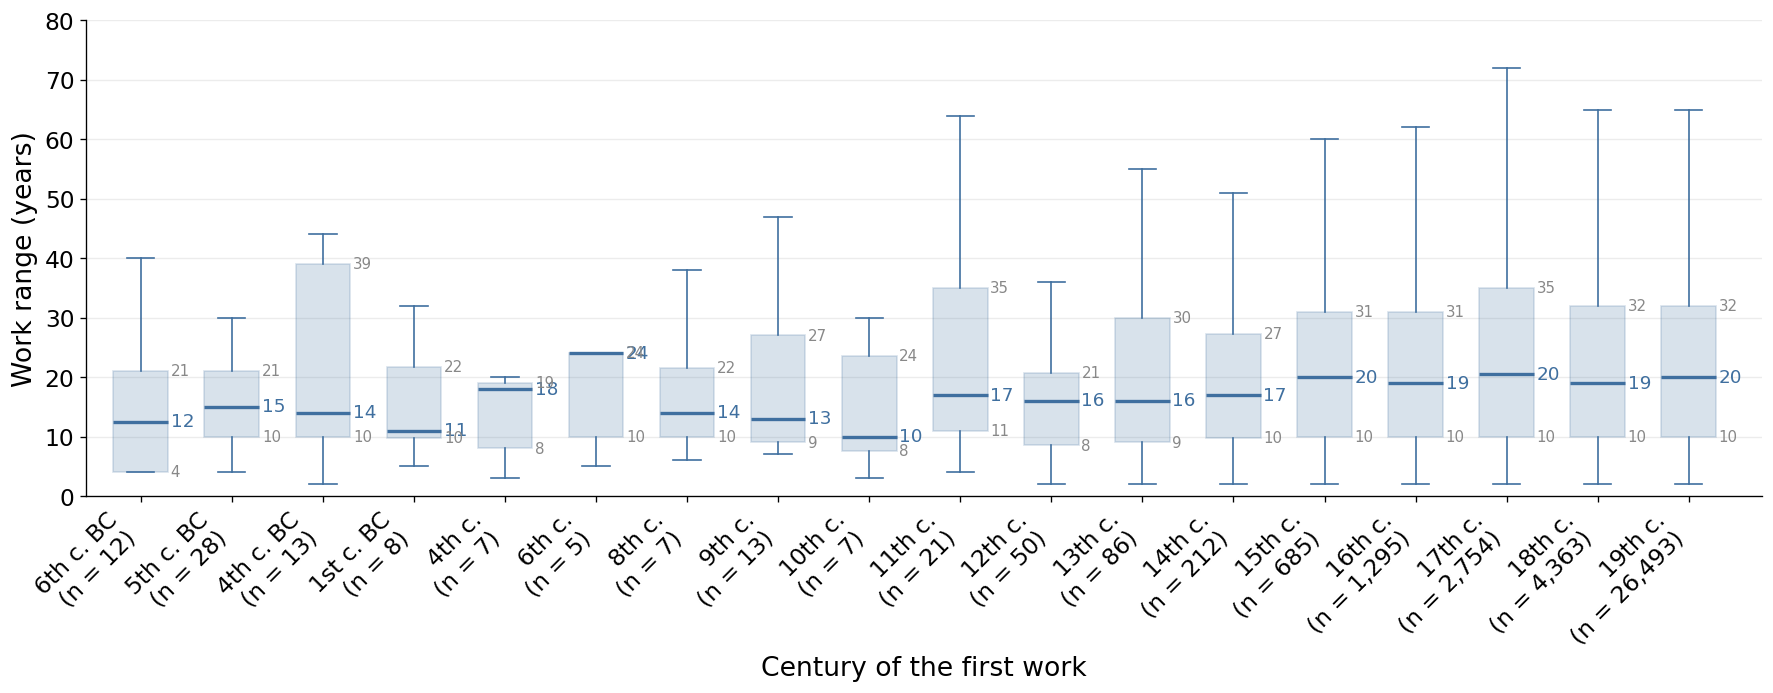

In [14]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
plot_centuries(ax, ranges, MAIN_LINE_COLOR, show_quartiles=True, show_counts=True)
ax.set_xlabel('Century of the first work')
ax.set_ylabel('Work range (years)')
plt.tight_layout()
plt.show()

### Length of the work ranges per century of their start, by occupational category
#### Data plotted

In [15]:
box_stats(ranges.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), ['meta_occupation', 'century'])

meta_occupation,century,individuals,low,median,high
str,i64,u32,f64,f64,f64
"""Culture""",-600,12,4.0,12.5,21.0
"""Culture""",-500,28,10.0,15.0,21.0
"""Culture""",-400,9,11.0,14.0,35.0
"""Culture""",-100,5,10.0,12.0,20.0
"""Culture""",0,1,7.0,7.0,7.0
"""Culture""",100,1,25.0,25.0,25.0
"""Culture""",700,3,13.5,15.0,21.5
"""Culture""",800,3,7.0,7.0,10.0
"""Culture""",900,4,17.25,23.5,26.25


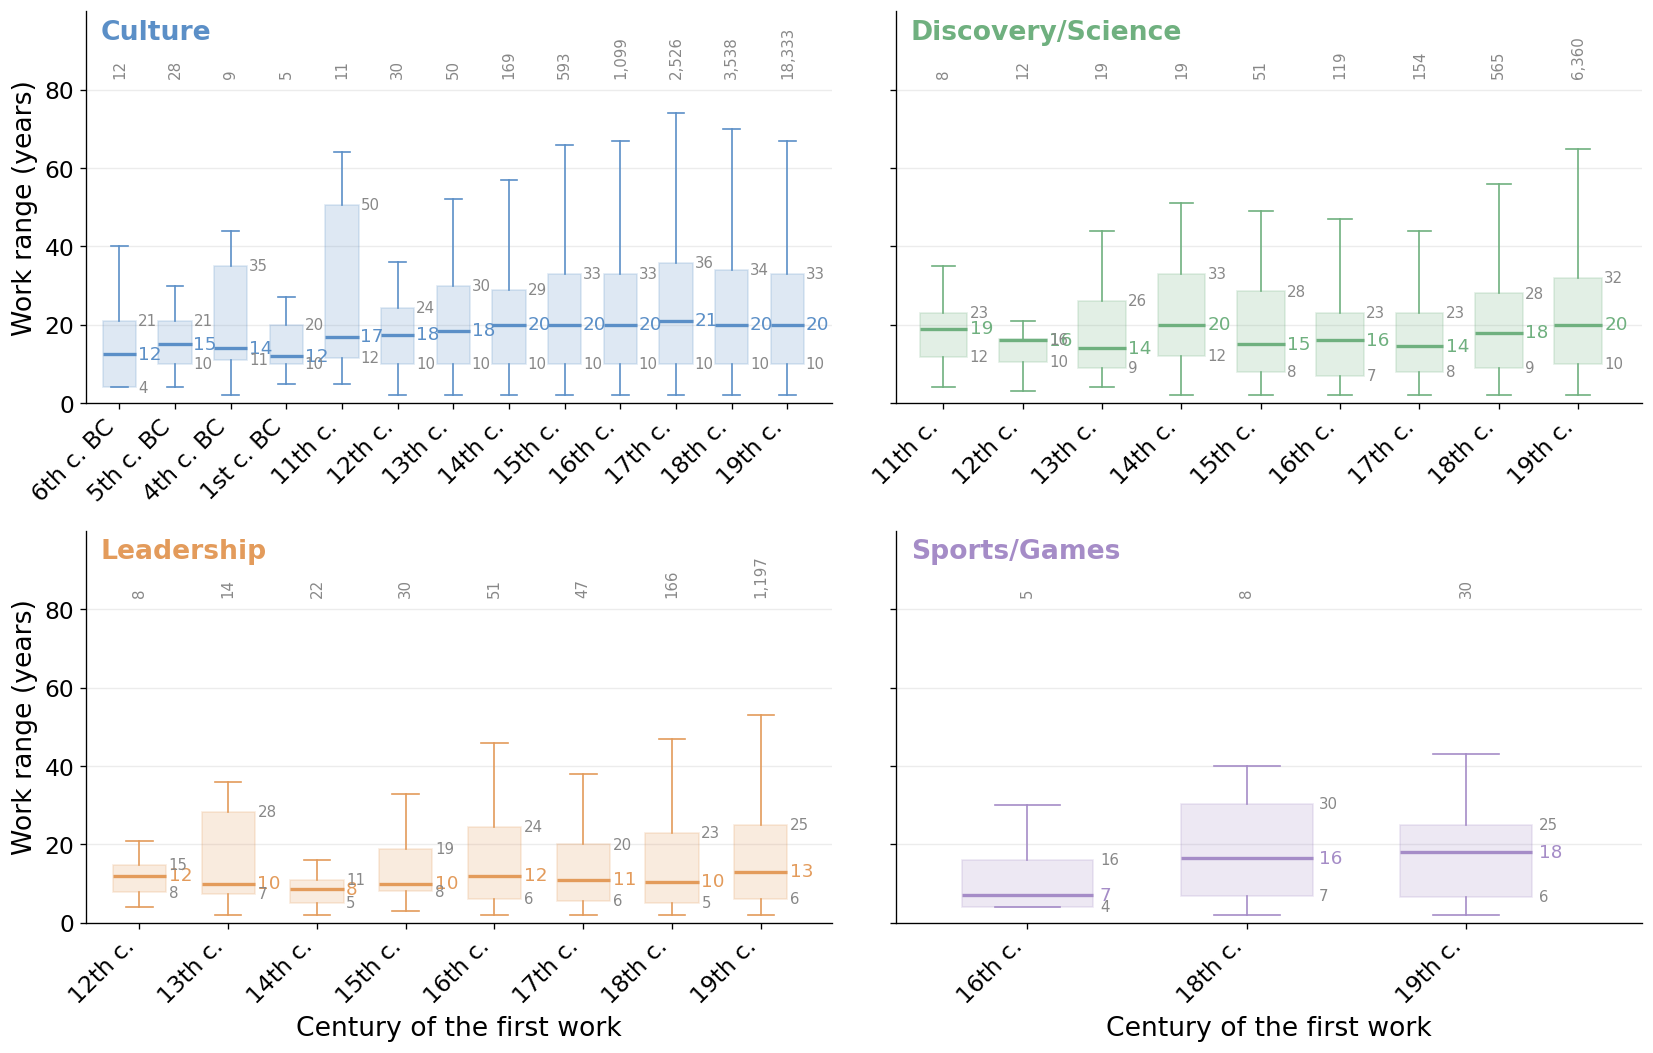

In [16]:
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_GRID, sharey=True)
for ax, (occupation, color) in zip(axes.flat, OCCUPATION_COLORS.items()):
    ax.text(0.02, 0.98, occupation, transform=ax.transAxes, fontsize=PANEL_LABEL_FONTSIZE, color=color, va='top', fontweight='bold')
    plot_centuries(ax, ranges.filter(pl.col('meta_occupation') == occupation), color, show_quartiles=True, counts_on_top=True)
for ax in axes[-1, :]:
    ax.set_xlabel('Century of the first work')
for ax in axes[:, 0]:
    ax.set_ylabel('Work range (years)')
plt.tight_layout()
plt.show()